# Batik Lestari — Analisis Penjualan Q3 2026

## 0. Setup

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 10, "axes.titlesize": 13, "axes.titleweight": "bold"})
pd.set_option("display.width", 120)

df = pd.read_csv("Batik Lestari Q3 Sales.csv", keep_default_na=False)
df.head()

,id_pesanan,tanggal_pesanan,channel,kota_pembeli,kategori,produk,harga_satuan,jumlah,diskon_persen,metode_bayar,status_pesanan,rating
0,BL-00001,2026-07-01,Shopee,Yogyakarta,Kemeja Pria,Kemeja Batik Parang Lengan Pendek,185000,1,5,Transfer Bank,Selesai,5.0
1,BL-00002,2026-07-01,Tokopedia,Pekalongan,Aksesoris,Scarf Batik Sutra,95000,1,10,COD,Selesai,4.0
2,BL-00003,2026-07-01,Toko Offline,Pekalongan,Kemeja Pria,Kemeja Batik Kawung Slim Fit,215000,1,10,QRIS,Selesai,5.0
3,BL-00004,2026-07-01,Toko Offline,Semarang,Kemeja Pria,Kemeja Batik Mega Mendung Lengan Panjang,245000,3,0,QRIS,Selesai,4.0
4,BL-00005,2026-07-01,Toko Offline,Jakarta,Outer,Outer Batik Kimono,159000,2,5,Kartu Debit,Selesai,4.0


## 1. Kenalan dengan Data

Lihat bentuk, tipe, dan ringkasan angka sebelum menyentuh apa pun.

In [ ]:
print("Jumlah baris & kolom:", df.shape)
print("Nama kolom:", df.columns.tolist())
df.head()

Jumlah baris & kolom: (1206, 12)
Nama kolom: ['id_pesanan', 'tanggal_pesanan', 'channel', 'kota_pembeli', 'kategori', 'produk', 'harga_satuan', 'jumlah', 'diskon_persen', 'metode_bayar', 'status_pesanan', 'rating']


,id_pesanan,tanggal_pesanan,channel,kota_pembeli,kategori,produk,harga_satuan,jumlah,diskon_persen,metode_bayar,status_pesanan,rating
0,BL-00001,2026-07-01,Shopee,Yogyakarta,Kemeja Pria,Kemeja Batik Parang Lengan Pendek,185000,1,5,Transfer Bank,Selesai,5.0
1,BL-00002,2026-07-01,Tokopedia,Pekalongan,Aksesoris,Scarf Batik Sutra,95000,1,10,COD,Selesai,4.0
2,BL-00003,2026-07-01,Toko Offline,Pekalongan,Kemeja Pria,Kemeja Batik Kawung Slim Fit,215000,1,10,QRIS,Selesai,5.0
3,BL-00004,2026-07-01,Toko Offline,Semarang,Kemeja Pria,Kemeja Batik Mega Mendung Lengan Panjang,245000,3,0,QRIS,Selesai,4.0
4,BL-00005,2026-07-01,Toko Offline,Jakarta,Outer,Outer Batik Kimono,159000,2,5,Kartu Debit,Selesai,4.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1206 entries, 0 to 1205
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   id_pesanan       1206 non-null   object
 1   tanggal_pesanan  1206 non-null   object
 2   channel          1206 non-null   object
 3   kota_pembeli     1206 non-null   object
 4   kategori         1206 non-null   object
 5   produk           1206 non-null   object
 6   harga_satuan     1206 non-null   int64 
 7   jumlah           1206 non-null   int64 
 8   diskon_persen    1206 non-null   int64 
 9   metode_bayar     1206 non-null   object
 10  status_pesanan   1206 non-null   object
 11  rating           1206 non-null   object
dtypes: int64(3), object(9)
memory usage: 113.2+ KB


In [ ]:
df.describe()

,harga_satuan,jumlah,diskon_persen
count,1206.000000,1206.000000,1206.000000
mean,167325.041459,1.862355,6.546434
std,92315.517879,1.498312,6.978978
min,35000.000000,1.000000,0.000000
25%,95000.000000,1.000000,0.000000
50%,185000.000000,1.000000,5.000000
75%,215000.000000,2.000000,10.000000
max,450000.000000,10.000000,25.000000


## 2. Membersihkan Data

In [ ]:
print("Baris duplikat persis :", df.duplicated().sum())
print("id_pesanan dobel      :", df.duplicated(subset=['id_pesanan']).sum())
print("id_pesanan unik       :", df['id_pesanan'].nunique(), "dari", len(df), "baris")
print()
print("Nilai unik kolom teks (mentah):")
for c in ['channel', 'kota_pembeli', 'metode_bayar', 'status_pesanan']:
    print(f"  {c:14} ({df[c].nunique()} nilai):", dict(df[c].value_counts()))
print()
print("Jumlah sel kosong per kolom:")
kosong = df.astype(str).apply(lambda s: (s.str.strip() == "")).sum()
print(kosong[kosong > 0].to_string())
print()
print("Spasi berlebih di kolom teks:")
for c in ['channel', 'kota_pembeli', 'kategori', 'produk', 'metode_bayar', 'status_pesanan']:
    print(f"  {c:14}:", int((df[c] != df[c].str.strip()).sum()))

Baris duplikat persis : 26
id_pesanan dobel      : 26
id_pesanan unik       : 1180 dari 1206 baris

Nilai unik kolom teks (mentah):
  channel        (7 nilai): {'Shopee': np.int64(404), 'TikTok Shop': np.int64(349), 'Tokopedia': np.int64(246), 'Toko Offline': np.int64(154), 'tiktok shop': np.int64(24), 'shopee': np.int64(16), 'Tiktok Shop ': np.int64(13)}
  kota_pembeli   (10 nilai): {'Jakarta': np.int64(273), 'Pekalongan': np.int64(166), 'Surabaya': np.int64(156), 'Bandung': np.int64(145), 'Yogyakarta': np.int64(108), 'Medan': np.int64(94), 'Semarang': np.int64(92), 'Makassar': np.int64(87), 'Denpasar': np.int64(54), '': np.int64(31)}
  metode_bayar   (7 nilai): {'E-Wallet': np.int64(341), 'COD': np.int64(332), 'Transfer Bank': np.int64(241), 'Paylater': np.int64(138), 'QRIS': np.int64(60), 'Tunai': np.int64(55), 'Kartu Debit': np.int64(39)}
  status_pesanan (4 nilai): {'Selesai': np.int64(1067), 'Dibatalkan': np.int64(87), 'Dikembalikan': np.int64(34), 'selesai': np.int64(18)}

Jumla

In [ ]:
df_clean = df.copy()

for col in ['channel', 'kota_pembeli', 'kategori', 'produk', 'metode_bayar', 'status_pesanan']:
    df_clean[col] = df_clean[col].str.strip()

df_clean['channel'] = df_clean['channel'].str.lower().map(
    {'shopee': 'Shopee', 'tiktok shop': 'TikTok Shop',
     'tokopedia': 'Tokopedia', 'toko offline': 'Toko Offline'})
df_clean['status_pesanan'] = df_clean['status_pesanan'].str.lower().map(
    {'selesai': 'Selesai', 'dibatalkan': 'Dibatalkan', 'dikembalikan': 'Dikembalikan'})

df_clean['kota_pembeli'] = df_clean['kota_pembeli'].replace('', 'Tidak Diketahui')
df_clean['rating'] = pd.to_numeric(df_clean['rating'].replace('', np.nan))

df_clean['tanggal_pesanan'] = pd.to_datetime(df_clean['tanggal_pesanan'])
for col in ['harga_satuan', 'jumlah', 'diskon_persen']:
    df_clean[col] = pd.to_numeric(df_clean[col])

# buang data dobel: hanya baris yang SAMA PERSIS di semua kolom (termasuk id_pesanan dan rating)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Baris sebelum cleaning :", len(df))
print("Baris sesudah cleaning :", len(df_clean))
print("Baris dibuang          :", len(df) - len(df_clean))
print("Cek id_pesanan unik    :", df_clean['id_pesanan'].nunique(), "dari", len(df_clean), "baris")

# transparansi: pesanan yang isinya mirip tapi id & rating beda (dipertahankan)
identitas = ['tanggal_pesanan', 'channel', 'kota_pembeli', 'kategori', 'produk',
             'harga_satuan', 'jumlah', 'diskon_persen', 'metode_bayar', 'status_pesanan']
mirip = df_clean[df_clean.duplicated(subset=identitas, keep=False)]
display(mirip[['id_pesanan'] + identitas + ['rating']])

Baris sebelum cleaning : 1206
Baris sesudah cleaning : 1180
Baris dibuang          : 26
Cek id_pesanan unik    : 1180 dari 1180 baris


,id_pesanan,tanggal_pesanan,channel,kota_pembeli,kategori,produk,harga_satuan,jumlah,diskon_persen,metode_bayar,status_pesanan,rating
508,BL-00509,2026-08-08,TikTok Shop,Jakarta,Kemeja Pria,Kemeja Batik Parang Lengan Pendek,185000,1,20,Transfer Bank,Selesai,3.0
516,BL-00517,2026-08-08,TikTok Shop,Jakarta,Kemeja Pria,Kemeja Batik Parang Lengan Pendek,185000,1,20,Transfer Bank,Selesai,5.0


## 3. Menyiapkan Kolom Baru

- `pendapatan_bersih = harga_satuan × jumlah × (1 − diskon_persen / 100)`
- `bulan` dari `tanggal_pesanan`

In [ ]:
df_clean['pendapatan_bersih'] = df_clean['harga_satuan'] * df_clean['jumlah'] * (1 - df_clean['diskon_persen'] / 100)
df_clean['bulan'] = df_clean['tanggal_pesanan'].dt.month

df_clean[['tanggal_pesanan', 'harga_satuan', 'jumlah', 'diskon_persen', 'pendapatan_bersih', 'bulan']].head()

,tanggal_pesanan,harga_satuan,jumlah,diskon_persen,pendapatan_bersih,bulan
0,2026-07-01,185000,1,5,175750.0,7
1,2026-07-01,95000,1,10,85500.0,7
2,2026-07-01,215000,1,10,193500.0,7
3,2026-07-01,245000,3,0,735000.0,7
4,2026-07-01,159000,2,5,302100.0,7


**Keputusan: pendapatan hanya dihitung dari pesanan berstatus `Selesai`.**
- `Dibatalkan` (84 pesanan) tidak menghasilkan uang, jadi tidak boleh dihitung.
- `Dikembalikan` (34 pesanan) uangnya dikembalikan ke pembeli, jadi juga dikeluarkan.
- Pesanan batal dan retur tetap dipakai untuk analisis masalah (P4, P5, P6 dan insight COD).

In [ ]:
print(df_clean['status_pesanan'].value_counts().to_string())
df_selesai = df_clean[df_clean['status_pesanan'] == 'Selesai'].copy()
print()
print("Pesanan Selesai:", len(df_selesai), "pesanan")
print("Total pendapatan bersih: Rp", f"{df_selesai['pendapatan_bersih'].sum():,.0f}")

status_pesanan
Selesai         1062
Dibatalkan        84
Dikembalikan      34

Pesanan Selesai: 1062 pesanan
Total pendapatan bersih: Rp 276,425,900


## 4. Menjawab Pertanyaan Bisnis Bu Ratna (P1–P6)

### P1. Channel dengan pendapatan bersih terbesar

In [ ]:
p1 = df_selesai.groupby('channel')['pendapatan_bersih'].sum().sort_values(ascending=False)
print("Pendapatan bersih per channel (juta Rp):")
print((p1 / 1e6).round(1).to_string())
print()
print("Porsi (%):")
print((p1 / p1.sum() * 100).round(1).to_string())

Pendapatan bersih per channel (juta Rp):
channel
Shopee          95.5
TikTok Shop     82.7
Tokopedia       50.0
Toko Offline    48.2

Porsi (%):
channel
Shopee          34.5
TikTok Shop     29.9
Tokopedia       18.1
Toko Offline    17.4


**P1:** **Shopee** juara dengan Rp 95,5 juta (**34,5%**), disusul **TikTok Shop** Rp 82,7 juta (29,9%). Dua marketplace ini menyumbang **64,5%** total pendapatan (Rp 178,2 juta dari Rp 276,4 juta).

### P2. Kategori paling laris (jumlah item) vs pendapatan terbesar

In [ ]:
p2 = df_selesai.groupby('kategori').agg(
    jumlah_item=('jumlah', 'sum'),
    pendapatan=('pendapatan_bersih', 'sum'),
    harga_rata=('harga_satuan', 'mean'))

print("Juara JUMLAH ITEM:")
print(df_selesai.groupby('kategori')['jumlah'].sum().sort_values(ascending=False).to_string())
print()
print("Juara PENDAPATAN:")
print((p2['pendapatan'].sort_values(ascending=False) / 1e6).round(1).to_string())
print()
print("Ringkasan:")
print(p2.assign(pendapatan_juta=(p2['pendapatan'] / 1e6).round(1))
        .drop(columns='pendapatan').sort_values('pendapatan_juta', ascending=False).to_string())

Juara JUMLAH ITEM:
kategori
Aksesoris       871
Kemeja Pria     450
Dress Wanita    268
Outer           227
Kain Batik      175

Juara PENDAPATAN:
kategori
Kemeja Pria     85.3
Dress Wanita    57.1
Aksesoris       49.2
Kain Batik      44.7
Outer           40.1

Ringkasan:
              jumlah_item     harga_rata  pendapatan_juta
kategori                                                 
Kemeja Pria           450  205284.697509             85.3
Dress Wanita          268  225165.680473             57.1
Aksesoris             871   61485.714286             49.2
Kain Batik            175  272198.275862             44.7
Outer                 227  192835.616438             40.1


**P2:** **Tidak sama.**
- Juara **jumlah item** = **Aksesoris** (871 item), tapi harganya murah (rata-rata Rp 61 ribu).
- Juara **pendapatan** = **Kemeja Pria** (Rp 85,3 juta), padahal jumlah itemnya hanya urutan kedua (450).

**Kenapa beda?** Karena **harga satuan**. Aksesoris laku banyak tapi murah, sedangkan Kemeja Pria mahal (rata-rata Rp 205 ribu), jadi sedikit item pun uangnya besar.

### P3. Tren pendapatan per bulan & per hari + tanggal kembar

In [ ]:
p3 = df_selesai.groupby('bulan')['pendapatan_bersih'].sum() / 1e6
print("Pendapatan per bulan (juta Rp):")
print(p3.round(1).to_string())

print("\nPendapatan per channel per bulan (juta Rp):")
per_channel = df_selesai.groupby(['channel', 'bulan'])['pendapatan_bersih'].sum().unstack() / 1e6
print(per_channel.round(1).to_string())
print("\nSelisih September vs Agustus per channel (juta Rp):")
print((per_channel[9] - per_channel[8]).round(1).sort_values().to_string())

kembar = pd.to_datetime(['2026-07-07', '2026-08-08', '2026-09-09'])
harian = df_selesai.groupby('tanggal_pesanan')['pendapatan_bersih'].sum()
rata = harian[~harian.index.isin(kembar)].mean()
print("\nRata-rata pendapatan hari biasa (juta Rp):", round(rata / 1e6, 2))
print("Tanggal kembar:")
for d in kembar:
    print(f"  {d.date()}: Rp {harian[d]:,.0f}  ({harian[d]/rata:.1f}x hari biasa)")

# apa yang berubah di tanggal kembar? (semua pesanan masuk)
df_clean['hari_kembar'] = df_clean['tanggal_pesanan'].isin(kembar)
cmp = df_clean.groupby('hari_kembar').agg(
    jumlah_pesanan=('id_pesanan', 'size'),
    nilai_per_pesanan=('pendapatan_bersih', 'mean'),
    diskon_rata=('diskon_persen', 'mean'),
    jumlah_hari=('tanggal_pesanan', 'nunique'))
cmp['pesanan_per_hari'] = cmp['jumlah_pesanan'] / cmp['jumlah_hari']
print("\nPerbandingan hari biasa (False) vs tanggal kembar (True):")
print(cmp.round(1).to_string())

print("\nPembanding: hari besar nasional 15 & 17 Agustus")
for d in pd.to_datetime(['2026-08-15', '2026-08-17']):
    dis = df_clean[df_clean['tanggal_pesanan'] == d]['diskon_persen'].mean()
    print(f"  {d.date()}: Rp {harian[d]:,.0f} | diskon rata-rata {dis:.1f}%")

Pendapatan per bulan (juta Rp):
bulan
7    91.6
8    99.7
9    85.2

Pendapatan per channel per bulan (juta Rp):
bulan            7     8     9
channel                       
Shopee        29.7  35.0  30.8
TikTok Shop   26.7  31.4  24.6
Toko Offline  19.3  16.2  12.7
Tokopedia     15.8  17.1  17.1

Selisih September vs Agustus per channel (juta Rp):
channel
TikTok Shop    -6.8
Shopee         -4.2
Toko Offline   -3.4
Tokopedia      -0.0

Rata-rata pendapatan hari biasa (juta Rp): 2.89
Tanggal kembar:
  2026-07-07: Rp 6,985,800  (2.4x hari biasa)
  2026-08-08: Rp 6,093,050  (2.1x hari biasa)
  2026-09-09: Rp 5,969,900  (2.1x hari biasa)

Perbandingan hari biasa (False) vs tanggal kembar (True):
             jumlah_pesanan  nilai_per_pesanan  diskon_rata  jumlah_hari  pesanan_per_hari
hari_kembar                                                                               
False                  1086           264066.0          5.5           89              12.2
True                     

**P3:** Juli Rp 91,6 jt → Agustus Rp 99,7 jt (naik) → September Rp 85,2 jt (turun Rp 14,5 jt). Penurunan September terbesar di TikTok Shop (−6,8 jt), Shopee (−4,2 jt), dan Toko Offline (−3,4 jt); Tokopedia stabil.

**Tanggal kembar terlihat jelas berbeda:** Rp 6,0–7,0 juta per hari, sekitar **2x** rata-rata hari biasa (Rp 2,9 juta). Lonjakannya datang dari jumlah pesanan (31 pesanan/hari vs 12 di hari biasa), tapi diskonnya juga jauh lebih dalam (rata-rata 18,9% vs 5,5%) sehingga nilai per pesanan turun (Rp 217 rb vs Rp 264 rb). Hari besar nasional 15 & 17 Agustus juga mencapai Rp 6,6–6,8 juta dengan diskon rata-rata hanya 2,7–5,4%.

### P4. Metode bayar paling sering dibatalkan

In [ ]:
p4 = pd.crosstab(df_clean['metode_bayar'], df_clean['status_pesanan'])
p4['% Dibatalkan'] = (p4['Dibatalkan'] / p4.sum(axis=1) * 100).round(1)
p4['% Dikembalikan'] = (p4['Dikembalikan'] / p4.sum(axis=1) * 100).round(1)
print(p4.sort_values('% Dibatalkan', ascending=False).to_string())

status_pesanan  Dibatalkan  Dikembalikan  Selesai  % Dibatalkan  % Dikembalikan
metode_bayar                                                                   
COD                     47            11      264          14.6             3.3
Paylater                12             5      119           8.8             3.5
E-Wallet                16             9      307           4.8             2.7
Transfer Bank            9             7      222           3.8             2.9
Kartu Debit              0             1       37           0.0             2.6
QRIS                     0             1       58           0.0             1.7
Tunai                    0             0       55           0.0             0.0


In [ ]:
mk = df_clean[df_clean['channel'] != 'Toko Offline']
print("% batal di marketplace, COD (True) vs non-COD (False):")
print(mk.assign(cod=mk['metode_bayar'].eq('COD')).groupby('cod')['status_pesanan']
        .apply(lambda x: (x == 'Dibatalkan').mean() * 100).round(1).to_string())

print("\nNilai pesanan yang dibatalkan per metode bayar (juta Rp):")
nilai_batal = df_clean[df_clean['status_pesanan'] == 'Dibatalkan'].groupby('metode_bayar')['pendapatan_bersih'].sum() / 1e6
print(nilai_batal.round(1).sort_values(ascending=False).to_string())
print("Total pesanan batal (juta Rp):", round(nilai_batal.sum(), 1))

% batal di marketplace, COD (True) vs non-COD (False):
cod
False     5.2
True     14.6

Nilai pesanan yang dibatalkan per metode bayar (juta Rp):
metode_bayar
COD              11.2
E-Wallet          3.8
Transfer Bank     2.4
Paylater          2.1
Total pesanan batal (juta Rp): 19.5


**P4:** **COD** paling sering dibatalkan: **14,6%** dari seluruh pesanan COD. Jauh di atas Paylater (8,8%), E-Wallet (4,8%), dan Transfer Bank (3,8%). QRIS, Tunai, dan Kartu Debit 0%.

### P5. Kota dengan pembeli terbanyak

In [ ]:
# 'Tidak Diketahui' tidak ikut ranking kota
kota = df_clean[df_clean['kota_pembeli'] != 'Tidak Diketahui']
p5 = kota['kota_pembeli'].value_counts()
p5p = (p5 / len(df_clean) * 100).round(1)
print(pd.DataFrame({'jumlah_pesanan': p5, 'persen': p5p}).to_string())

print("\nPendapatan (pesanan Selesai) per kota, juta Rp:")
print((df_selesai[df_selesai['kota_pembeli'] != 'Tidak Diketahui']
       .groupby('kota_pembeli')['pendapatan_bersih'].sum().sort_values(ascending=False) / 1e6).round(1).to_string())

print("\nPesanan Pekalongan per channel:")
print(df_clean[df_clean['kota_pembeli'] == 'Pekalongan']['channel'].value_counts().to_string())

              jumlah_pesanan  persen
kota_pembeli                        
Jakarta                  267    22.6
Pekalongan               165    14.0
Surabaya                 149    12.6
Bandung                  143    12.1
Yogyakarta               106     9.0
Medan                     92     7.8
Semarang                  91     7.7
Makassar                  83     7.0
Denpasar                  53     4.5

Pendapatan (pesanan Selesai) per kota, juta Rp:
kota_pembeli
Jakarta       57.1
Pekalongan    47.5
Bandung       32.0
Surabaya      31.9
Yogyakarta    26.0
Medan         22.0
Semarang      21.4
Makassar      19.1
Denpasar      13.5

Pesanan Pekalongan per channel:
channel
Toko Offline    94
Shopee          29
TikTok Shop     23
Tokopedia       19


**P5:** **Jakarta** terbanyak (267 pesanan, 22,6%), disusul Pekalongan (165) dan Surabaya (149). Catatan: data tidak punya ID pembeli, jadi yang dihitung adalah jumlah pesanan, bukan orangnya. 94 dari 165 pesanan Pekalongan datang dari Toko Offline di kota itu sendiri.

### P6. Rata-rata rating per kategori

In [ ]:
p6 = df_clean.groupby('kategori')['rating'].agg(['mean', 'count']).round(2).sort_values('mean', ascending=False)
print(p6.to_string())
print()
missing_rating = df_clean[df_clean['rating'].isna()]
print('Rating kosong:', int(missing_rating.shape[0]), 'dari', len(df_clean))
print('Rincian status pada rating kosong:')
print(missing_rating['status_pesanan'].value_counts().reindex(['Selesai', 'Dibatalkan', 'Dikembalikan'], fill_value=0).to_string())

              mean  count
kategori                 
Kain Batik    4.21     98
Aksesoris     4.13    294
Outer         4.09    122
Kemeja Pria   4.04    239
Dress Wanita  4.03    159

Rating kosong: 268 dari 1180
Rincian status pada rating kosong:
status_pesanan
Selesai         174
Dibatalkan       84
Dikembalikan     10


**P6:** Rating antar kategori **merata tinggi**: Kain Batik tertinggi (4,21), lalu Aksesoris (4,13), Outer (4,09), Kemeja Pria (4,04), dan Dress Wanita (4,03). Rating kosong 268 dari 1.180 pesanan: 84 karena dibatalkan, 174 pesanan selesai yang tidak diberi rating (16,4% dari yang selesai), dan 10 dikembalikan.

## 5. Visualisasi

**Grafik 1 — Bar chart: pendapatan per channel.**

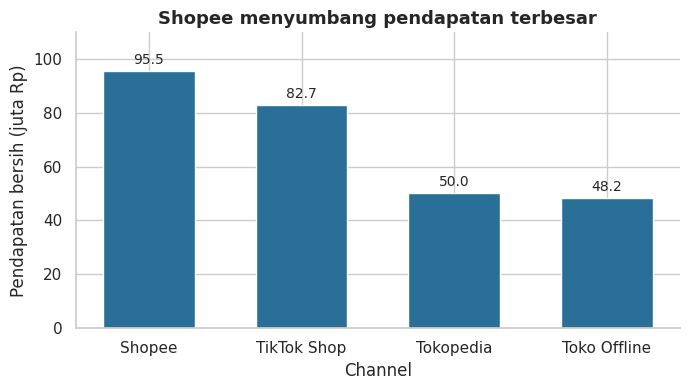

In [ ]:
p1 = (df_selesai.groupby('channel')['pendapatan_bersih'].sum().sort_values(ascending=False) / 1e6)

plt.figure(figsize=(7, 4))
bars = plt.bar(p1.index, p1.values, color='#2a6f97', width=0.6)
plt.bar_label(bars, fmt='%.1f', padding=3, fontsize=10)
plt.title('Shopee menyumbang pendapatan terbesar')
plt.xlabel('Channel')
plt.ylabel('Pendapatan bersih (juta Rp)')
plt.ylim(0, p1.max() * 1.15)
sns.despine()
plt.tight_layout()
plt.show()

G1: Shopee (Rp 95,5 jt) dan TikTok Shop (Rp 82,7 jt) bersama menyumbang 64,5% pendapatan, sedangkan Tokopedia dan Toko Offline masing-masing sekitar Rp 50 jt.

**Grafik 2 — Line chart: tren pendapatan per bulan.**

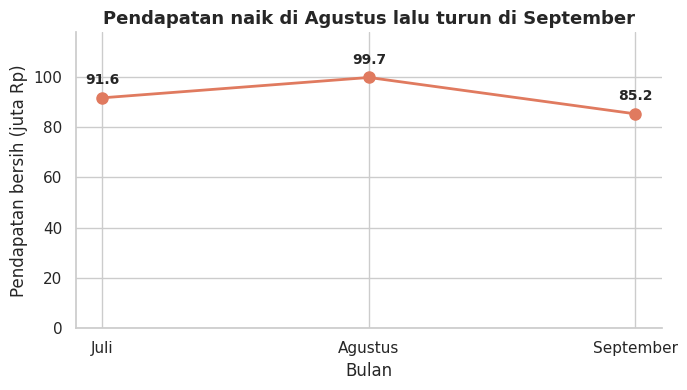

In [ ]:
p3 = df_selesai.groupby('bulan')['pendapatan_bersih'].sum() / 1e6

plt.figure(figsize=(7, 4))
plt.plot(p3.index, p3.values, marker='o', color='#e07a5f', linewidth=2, markersize=8)
for x, y in p3.items():
    plt.annotate(f'{y:.1f}', (x, y), textcoords='offset points', xytext=(0, 10),
                 ha='center', fontsize=10, fontweight='bold')
plt.xticks([7, 8, 9], ['Juli', 'Agustus', 'September'])
plt.title('Pendapatan naik di Agustus lalu turun di September')
plt.xlabel('Bulan')
plt.ylabel('Pendapatan bersih (juta Rp)')
plt.ylim(0, p3.max() * 1.18)
sns.despine()
plt.tight_layout()
plt.show()

G2: Pendapatan naik dari Rp 91,6 jt (Juli) ke Rp 99,7 jt (Agustus), lalu turun ke Rp 85,2 jt (September).

**Grafik 3 — Bar chart: jumlah item per kategori (juara volume).**

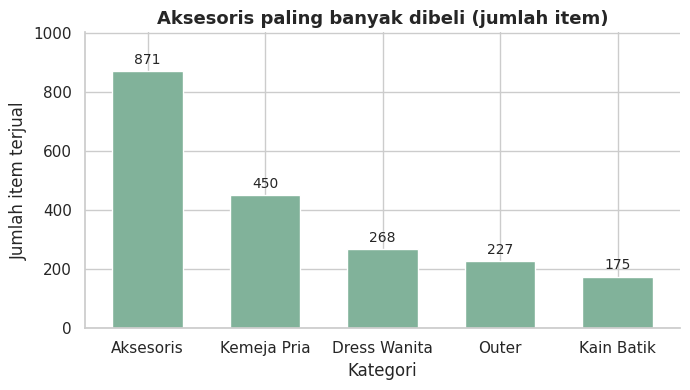

In [ ]:
unit = df_selesai.groupby('kategori')['jumlah'].sum().sort_values(ascending=False)

plt.figure(figsize=(7, 4))
bars = plt.bar(unit.index, unit.values, color='#81b29a', width=0.6)
plt.bar_label(bars, fmt='%d', padding=3, fontsize=10)
plt.title('Aksesoris paling banyak dibeli (jumlah item)')
plt.xlabel('Kategori')
plt.ylabel('Jumlah item terjual')
plt.ylim(0, unit.max() * 1.15)
sns.despine()
plt.tight_layout()
plt.show()

G3: Aksesoris terjual 871 item, hampir dua kali lipat Kemeja Pria di urutan kedua (450 item).

**Grafik 4 — Bar chart: pendapatan per kategori (juara uang).**

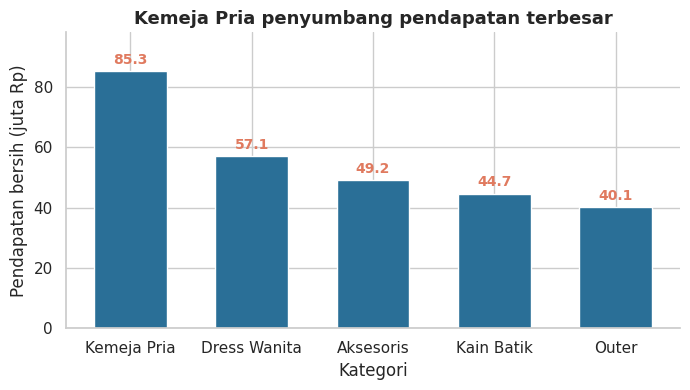

In [ ]:
uang = (df_selesai.groupby('kategori')['pendapatan_bersih'].sum().sort_values(ascending=False) / 1e6)

plt.figure(figsize=(7, 4))
bars = plt.bar(uang.index, uang.values, color='#2a6f97', width=0.6)
plt.bar_label(bars, fmt='%.1f', padding=3, fontsize=10, color='#e07a5f', fontweight='bold')
plt.title('Kemeja Pria penyumbang pendapatan terbesar')
plt.xlabel('Kategori')
plt.ylabel('Pendapatan bersih (juta Rp)')
plt.ylim(0, uang.max() * 1.15)
sns.despine()
plt.tight_layout()
plt.show()

G4: Kemeja Pria menghasilkan Rp 85,3 jt, jauh di atas Dress Wanita (Rp 57,1 jt); Aksesoris yang paling banyak terjual hanya di urutan ketiga (Rp 49,2 jt).

**Grafik 5 — Seaborn: persentase pesanan dibatalkan per metode bayar.**

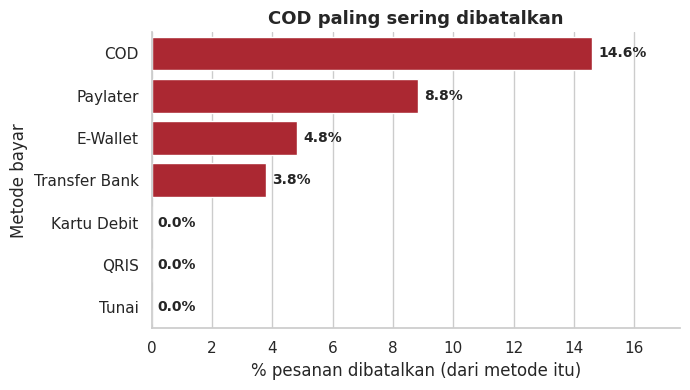

In [ ]:
batal = (pd.crosstab(df_clean['metode_bayar'], df_clean['status_pesanan'], normalize='index')['Dibatalkan'] * 100)
batal = batal.sort_values(ascending=False)

plt.figure(figsize=(7, 4))
ax = sns.barplot(x=batal.values, y=batal.index, color='#c1121f')
for i, v in enumerate(batal.values):
    ax.text(v + 0.2, i, f'{v:.1f}%', va='center', fontsize=10, fontweight='bold')
plt.title('COD paling sering dibatalkan')
plt.xlabel('% pesanan dibatalkan (dari metode itu)')
plt.ylabel('Metode bayar')
plt.xlim(0, batal.max() * 1.2)
sns.despine()
plt.tight_layout()
plt.show()

G5: COD dibatalkan 14,6%, hampir 4 kali lipat Transfer Bank (3,8%); QRIS, Tunai, dan Kartu Debit tidak ada yang batal.

**Grafik 6 — Line chart: pendapatan harian, tanggal kembar ditandai.**

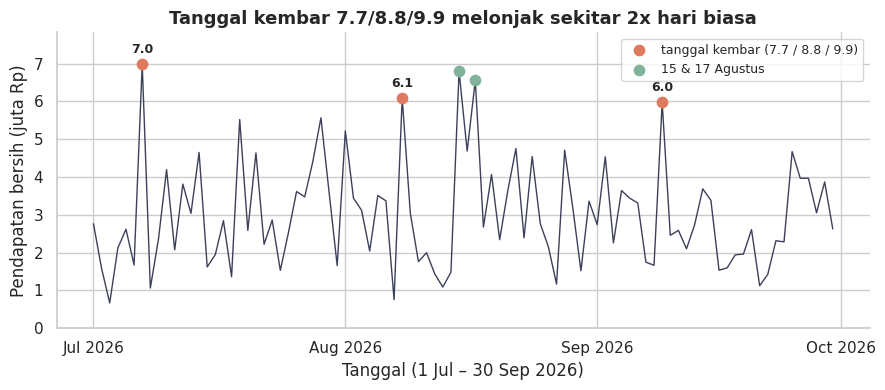

In [ ]:
import matplotlib.dates as mdates

harian = df_selesai.groupby('tanggal_pesanan')['pendapatan_bersih'].sum() / 1e6
kembar = pd.to_datetime(['2026-07-07', '2026-08-08', '2026-09-09'])
agustusan = pd.to_datetime(['2026-08-15', '2026-08-17'])

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(harian.index, harian.values, color='#3d405b', linewidth=1)
ky = harian.reindex(kembar).values
ax.scatter(kembar, ky, color='#e07a5f', s=55, zorder=5, label='tanggal kembar (7.7 / 8.8 / 9.9)')
ax.scatter(agustusan, harian.reindex(agustusan).values, color='#81b29a', s=55, zorder=5, label='15 & 17 Agustus')
for d, y in zip(kembar, ky):
    ax.annotate(f'{y:.1f}', (d, y), textcoords='offset points', xytext=(0, 8),
                ha='center', fontsize=9, fontweight='bold')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.legend(loc='upper right', fontsize=9)
ax.set_title('Tanggal kembar 7.7/8.8/9.9 melonjak sekitar 2x hari biasa')
ax.set_xlabel('Tanggal (1 Jul – 30 Sep 2026)')
ax.set_ylabel('Pendapatan bersih (juta Rp)')
ax.set_ylim(0, harian.max() * 1.12)
sns.despine()
plt.tight_layout()
plt.show()

## 6. Insight & Rekomendasi untuk Kuartal 4

**3 Insight Utama**

1. **Shopee dan TikTok Shop adalah mesin penjualan Batik Lestari, terutama di tanggal kembar.** Keduanya menyumbang Rp 178,2 juta atau 64,5% dari total Rp 276,4 juta. Di tanggal kembar Q3 (7.7, 8.8, 9.9), pendapatan harian Rp 6,0–7,0 juta atau sekitar 2x hari biasa (Rp 2,9 juta), dan semuanya datang dari marketplace. Sebaliknya Toko Offline turun tiap bulan (Rp 19,3 → 16,2 → 12,7 juta).

2. **Produk terlaris belum tentu penghasil uang terbesar.** Aksesoris terjual paling banyak (871 item) tapi harganya murah (rata-rata Rp 61 ribu). Kemeja Pria penghasil uang terbesar (Rp 85,3 juta, 31% dari total), dan satu produk saja, Kemeja Batik Parang Lengan Pendek, menyumbang Rp 45,3 juta (16%). Di tanggal kembar, Kemeja Pria dan Aksesoris menyumbang 62% pendapatan (hari biasa 49%).

3. **COD adalah sumber pesanan batal terbesar.** 14,6% pesanan COD batal, hampir 4x lipat Transfer Bank (3,8%). Di marketplace, pesanan non-COD hanya batal 5,2%. Pada catatan berstatus Dibatalkan, nilai hasil perhitungan `pendapatan_bersih` mencapai Rp 19,5 juta; Rp 11,2 juta (57%) terkait COD. Angka ini adalah nilai kalkulasi pada pesanan yang dibatalkan, bukan pendapatan aktual yang terbukti hilang atau laba yang pasti dapat dipulihkan.

**3 Rekomendasi untuk Bu Ratna**

1. **Hari Batik Nasional (2 Oktober): jadikan Kemeja Pria, terutama Kemeja Batik Parang Lengan Pendek, wajah promo di Shopee dan TikTok Shop.** Alasannya, Kemeja Pria produk penghasil uang terbesar dan dua marketplace itu menyumbang 64,5% pendapatan. Hari besar nasional bisa laku tanpa diskon dalam: 15 dan 17 Agustus menghasilkan Rp 6,6–6,8 juta per hari dengan diskon rata-rata hanya 2,7–5,4%. Mulai dengan diskon kecil dan amankan stok kemeja sejak akhir September.

2. **10.10, 11.11, dan 12.12: siapkan stok untuk sekitar 2,5x pesanan hari biasa dan batasi diskon.** Di Q3, tanggal kembar menerima 31 pesanan per hari (hari biasa 12). Prioritaskan stok Kemeja Pria dan Aksesoris (62% pendapatan tanggal kembar). Tetapkan batas diskon karena diskon rata-rata 18,9% membuat nilai per pesanan turun dari Rp 264 ribu menjadi Rp 217 ribu.

3. **Kurangi pembatalan COD sebelum musim ramai.** Minta konfirmasi ulang lewat WhatsApp untuk setiap pesanan COD sebelum dikirim, dan beri insentif kecil (misalnya gratis ongkir) agar pembeli memilih E-Wallet atau Transfer Bank. Nilai Rp 11,2 juta tersebut dapat dijadikan dasar pemantauan, bukan asumsi bahwa seluruhnya dapat dipulihkan. Ukur perubahan tingkat pembatalan, pesanan selesai, dan biaya operasional sebelum menyimpulkan dampak uji konfirmasi.

### Temuan tambahan (pendukung, di luar 3 insight utama)
- **Hari terlemah:** Kamis rata-rata Rp 2,2 juta/hari dan Jumat Rp 2,6 juta, sedangkan Sabtu-Minggu sekitar Rp 3,3 juta (dihitung tanpa tanggal kembar). Cukup indikatif tapi baru 13 Kamis, jadi sebaiknya diuji lewat flash sale kecil.
- **Toko Offline** punya nilai per pesanan tertinggi (Rp 321 ribu) dan 0% batal, tapi 0% batal itu wajar karena offline memang tidak punya COD/e-wallet/paylater.
- **Tokopedia** pembatalan tertinggi (10,9%), tapi selisihnya dengan channel lain belum cukup kuat secara statistik; pantau saja.
- **Pembayaran:** COD turun dari 30,5% (Juli) ke 25,6% (September), Transfer Bank naik dari 16,3% ke 24,3%.
- **Keterbatasan:** hanya 3 bulan, tidak ada data biaya/margin, dan tidak ada ID pembeli (yang dihitung pesanan, bukan orang).

### Rekomendasi tambahan

- **Kejar hari lemah.** Gelar flash sale/promo di **Kamis & Jumat** supaya penjualan lebih rata sepanjang minggu.

- **Hipotesis bundling aksesoris dengan produk bernilai tinggi.** Sebanyak 511 dari 1.180 catatan (43,3%) memiliki jumlah unit lebih dari satu. Namun, kolom `jumlah` tidak membuktikan bahwa satu pesanan berisi beberapa jenis produk; kuantitas tersebut bisa berupa beberapa unit dari SKU yang sama. Uji bundling sebagai pilot, bukan sebagai kesimpulan yang sudah terbukti.

- **Jadikan *Kemeja Batik Parang Lengan Pendek* wajah promo Q4** (produk nilai penjualan terbesar), bukan sekadar "kemeja" secara umum.

- **Tangani pembatalan di Tokopedia juga**, bukan hanya COD (Tokopedia 10,9% batal).

- **Pertahankan kanal Toko Offline** (nilai per pesanan tertinggi & paling sehat) meski trennya menurun.